# 03 — Global Energy Trends

This notebook studies the World aggregate as a time series and keeps total energy, electricity generation, and source-level generation conceptually separate.

> **Reading guide:** Each analysis section follows the same pattern: question → method → code → interpretation. The conclusion directly below each major code block explains what the output means and what it does *not* establish.

## 1. Why use the World aggregate?

**Question.** How have global energy and electricity indicators changed over time?

Where the source provides a `World` row for an indicator, I use that series directly. I do not add global aggregate rows to country rows. I also show valid observations by year so that changes in coverage are not mistaken for changes in the energy system.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "owid_energy.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "owid_energy.csv"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["savefig.dpi"] = 160

raw = pd.read_csv(DATA_PATH, low_memory=False)
df = raw.copy()
print(f"Loaded {DATA_PATH.name}: {df.shape[0]:,} rows × {df.shape[1]:,} columns")

world = df.loc[df["country"].eq("World")].sort_values("year").copy()
trend_metrics = [
    "total_energy_twh", "total_energy_per_capita_kwh", "electricity_generation_twh",
    "renewables_energy_twh", "fossil_fuels_energy_twh", "renewables_electricity_twh",
    "fossil_fuels_electricity_twh", "solar_electricity_twh", "wind_electricity_twh",
    "electricity_carbon_intensity_gco2eq_per_kwh", "electricity_emissions_mtco2eq"
]
trend_metrics = [c for c in trend_metrics if c in world.columns]
world[["year"] + trend_metrics].to_csv(TABLE_DIR / "world_trends.csv", index=False)
display(world[["year"] + trend_metrics].tail(12))

Loaded owid_energy.csv: 19,494 rows × 130 columns


,year,total_energy_twh,total_energy_per_capita_kwh,electricity_generation_twh,renewables_energy_twh,fossil_fuels_energy_twh,renewables_electricity_twh,fossil_fuels_electricity_twh,solar_electricity_twh,wind_electricity_twh,electricity_carbon_intensity_gco2eq_per_kwh,electricity_emissions_mtco2eq
19092,2014,144408.34,19563.242,23747.07,7668.1206,129038.61,5286.72,15961.62,197.74,706.10,544.73,12935.69
19093,2015,145499.62,19476.578,24002.35,8016.8545,129677.20,5512.64,15956.78,256.01,829.63,533.38,12802.33
19094,2016,146893.38,19434.057,24694.51,8453.3040,130518.70,5860.47,16262.99,327.47,960.30,525.30,12972.07
19095,2017,149727.25,19583.408,25441.04,8905.4420,132830.90,6224.33,16622.48,444.65,1139.44,522.04,13281.24
19096,2018,153618.12,19873.229,26464.49,9523.8890,135913.22,6639.60,17166.19,575.16,1268.14,518.51,13722.02
19097,2019,154620.70,19794.506,26832.42,10028.2660,136221.16,6995.61,17082.73,697.94,1420.96,505.75,13570.59
19098,2020,147985.30,18763.190,26723.37,10508.3430,129419.04,7479.17,16595.87,853.39,1591.47,492.11,13150.74
19099,2021,155558.44,19556.156,28259.07,11078.5980,136104.56,7941.26,17555.37,1053.99,1856.94,494.81,13982.89
19100,2022,157938.77,19689.658,28917.76,11753.3920,138189.34,8521.99,17756.13,1333.12,2107.66,489.52,14155.80
19101,2023,160876.92,19881.635,29665.34,12391.2290,140309.28,8995.45,17972.15,1664.14,2319.18,483.18,14333.67


### Conclusion

The World series is the preferred starting point for global trend questions when the relevant measure is available. It avoids double counting the same energy system across a global aggregate and its component countries. Before making a claim about long-run change, inspect gaps and verify that the selected indicator is present at both endpoints.

## 2. Long-run energy and electricity trends

**Question.** Do energy consumption and electricity generation follow the same trajectory?

These are separate systems: total energy includes uses beyond electricity generation. I plot each indicator on its own axis rather than combining different units into one scale.

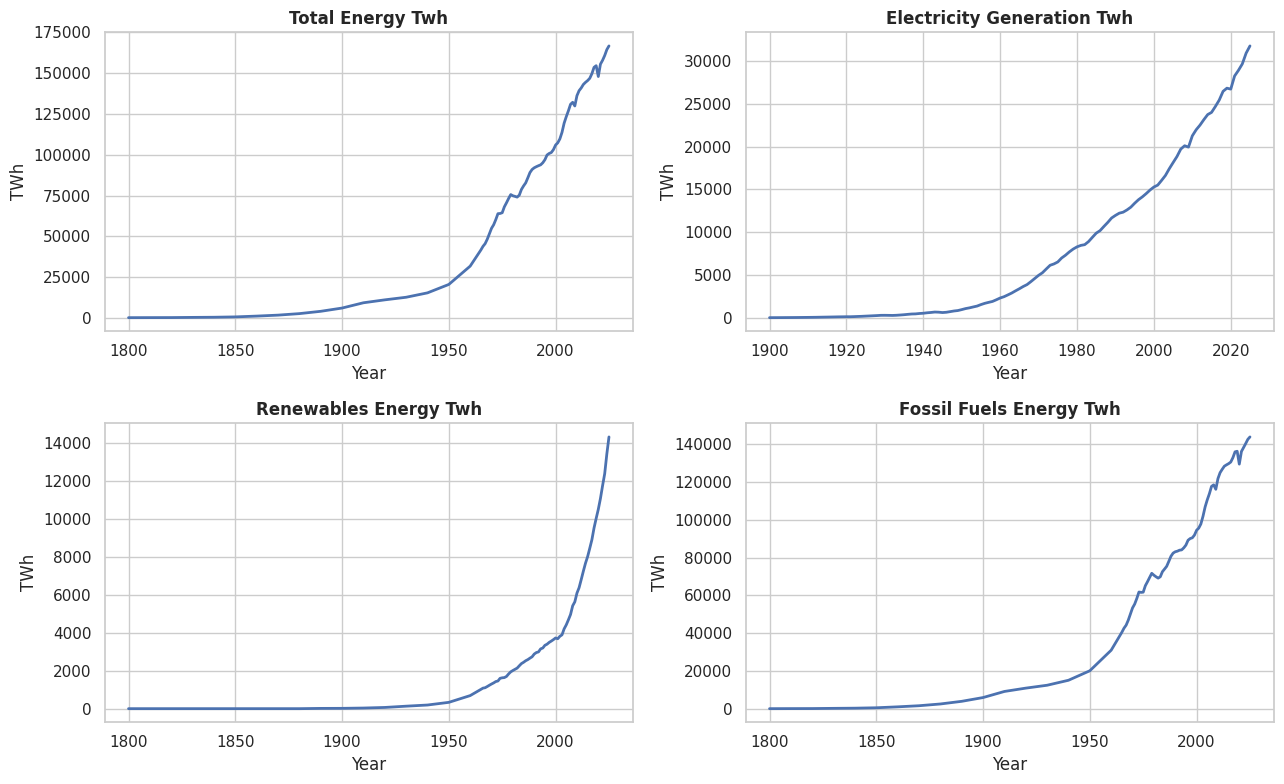

In [2]:
plot_metrics = [c for c in ["total_energy_twh", "electricity_generation_twh",
                            "renewables_energy_twh", "fossil_fuels_energy_twh"] if c in world.columns]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, plot_metrics):
    subset = world[["year", col]].dropna()
    ax.plot(subset["year"], subset[col], linewidth=2)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Year")
    ax.set_ylabel("TWh")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_world_energy_and_electricity_trends.png", bbox_inches="tight")
plt.show()

### Conclusion

Compare the shapes and turning points, not just the end values. A rise in renewable energy or renewable electricity does not by itself prove that fossil-fuel use has fallen in absolute terms; total demand may also have grown. Any trend claim should be supported by the corresponding source-level and total series.

## 3. Electricity mix over time

**Question.** How have major electricity sources changed in absolute generation?

I compare generation in TWh for coal, gas, hydro, nuclear, solar and wind. I avoid stacking these values until the availability and category definitions are confirmed to be mutually compatible.

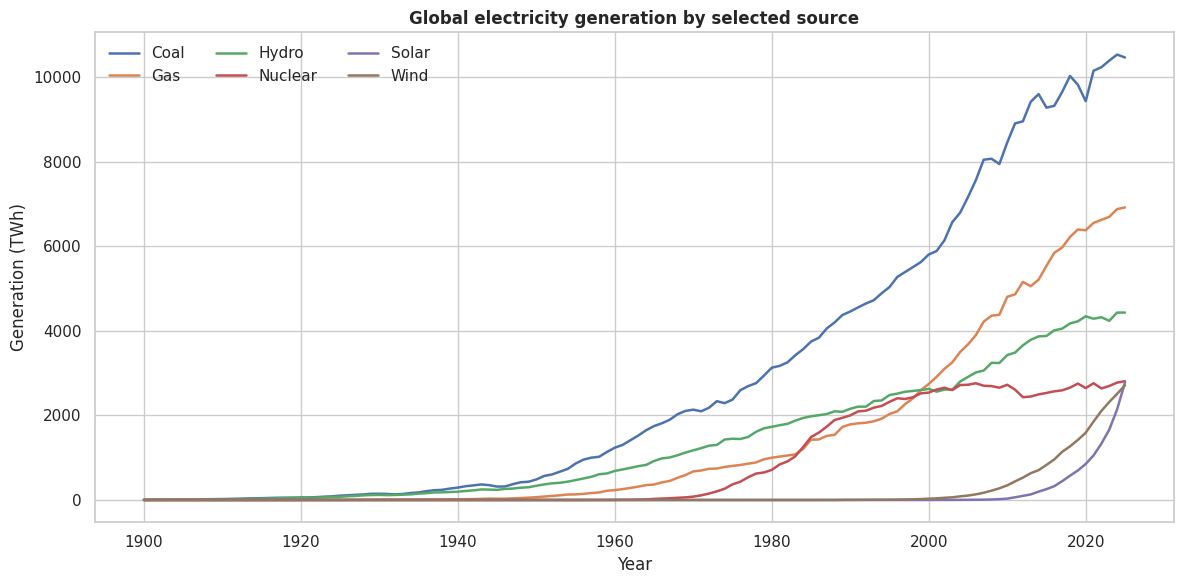

In [3]:
source_metrics = [c for c in ["coal_electricity_twh", "gas_electricity_twh", "hydro_electricity_twh",
                              "nuclear_electricity_twh", "solar_electricity_twh", "wind_electricity_twh"] if c in world.columns]
fig, ax = plt.subplots(figsize=(12, 6))
for col in source_metrics:
    s = world[["year", col]].dropna()
    ax.plot(s["year"], s[col], label=col.replace("_electricity_twh", "").title(), linewidth=1.8)
ax.set(title="Global electricity generation by selected source", xlabel="Year", ylabel="Generation (TWh)")
ax.legend(ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "06_world_electricity_sources.png", bbox_inches="tight")
plt.show()

### Conclusion

Absolute generation shows the size of each source, not its share of the total. Solar or wind can grow quickly from a small base while fossil generation remains stable or rises. Share-based and absolute-change measures should therefore be read together.

## 4. Endpoint changes and compound growth

**Question.** What changed between the first and last valid observations for each global series?

I calculate endpoint change and CAGR only where both endpoints are positive and the year span is greater than zero. CAGR summarizes the average annualized change between endpoints and does not describe every intermediate year.

In [4]:
endpoint_rows = []
for col in trend_metrics:
    s = world[["year", col]].dropna().sort_values("year")
    if len(s) < 2: continue
    first, last = s.iloc[0], s.iloc[-1]
    start_val, end_val = float(first[col]), float(last[col])
    span = int(last["year"] - first["year"])
    pct = ((end_val / start_val) - 1) * 100 if start_val != 0 else np.nan
    cagr = ((end_val / start_val) ** (1 / span) - 1) * 100 if start_val > 0 and end_val > 0 and span > 0 else np.nan
    endpoint_rows.append({"indicator": col, "start_year": int(first["year"]), "start_value": start_val,
                          "end_year": int(last["year"]), "end_value": end_val,
                          "absolute_change": end_val - start_val, "pct_change": pct, "cagr_pct": cagr,
                          "valid_observations": int(len(s))})
endpoint_table = pd.DataFrame(endpoint_rows)
endpoint_table.to_csv(TABLE_DIR / "world_trend_endpoint_changes.csv", index=False)
display(endpoint_table.round(3))

,indicator,start_year,start_value,end_year,end_value,absolute_change,pct_change,cagr_pct,valid_observations
0,total_energy_twh,1800,97.000,2025,166753.600,166656.600,171810.928,3.366,78
1,total_energy_per_capita_kwh,1800,98.667,2025,20257.705,20159.038,20431.388,2.395,78
2,electricity_generation_twh,1900,6.359,2025,31772.350,31765.991,499562.827,7.051,126
3,renewables_energy_twh,1800,0.000,2025,14325.500,14325.500,NaN,NaN,78
4,fossil_fuels_energy_twh,1800,97.000,2025,143805.690,143708.690,148153.289,3.298,78
5,renewables_electricity_twh,1900,2.621,2025,10726.490,10723.869,409095.140,6.880,126
6,fossil_fuels_electricity_twh,1900,3.737,2025,18234.290,18230.553,487787.686,7.030,126
7,solar_electricity_twh,1900,0.000,2025,2778.640,2778.640,NaN,NaN,126
8,wind_electricity_twh,1900,0.000,2025,2713.140,2713.140,NaN,NaN,126
9,electricity_carbon_intensity_gco2eq_per_kwh,2000,527.260,2025,458.290,-68.970,-13.081,-0.559,26


### Conclusion

Endpoint comparisons are transparent and reproducible, but they can be sensitive to unusual first or last observations. CAGR is undefined or misleading for non-positive baselines, so those cases are left missing. The table reports the actual endpoints used for each variable rather than assuming a common start year.